In [16]:
import helpy
import pandas as pd
from single_analysis import Analysis

pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', 10)

In [2]:
analysis_df = helpy.get_analysis_df(.08, 100, 3)

In [3]:
X, X_train, X_test, y_train, y_test = helpy.get_train_test_split(analysis_df)

In [4]:
# list of models to test effectiveness of
training_range = (2007, 2020)
testing_range = (2021, 2025)

base_analysis = Analysis(analysis_df, training_range=training_range, testing_range=testing_range, include_plus=False)

base_analysis.get_predictors(velo_fip=True, no_fip=True, movement=True, usage=True)

In [5]:
base_analysis.predictors

{'Residuals': <fip_predictor.FIP_Predictor at 0x75b23c63cad0>,
 'Usage': <fip_predictor.FIP_Predictor at 0x75b24521f8f0>,
 'Regular Movement': <fip_predictor.FIP_Predictor at 0x75b23c2c4230>,
 'Baseline': <fip_predictor.FIP_Predictor at 0x75b23c2c4170>,
 'No FIP': <fip_predictor.FIP_Predictor at 0x75b23c2c4710>,
 'Velo + FIP': <fip_predictor.FIP_Predictor at 0x75b28dfe7da0>}

In [6]:
base_analysis.predictor_results.sort_values('R2', ascending=False)

,Feature Set,Model,MAE,RMSE,R2
23,Velo + FIP,GAM,12.320428,15.331999,0.266837
1,Residuals,XGBoost,12.142887,15.334099,0.266637
2,Residuals,Random Forest,12.181163,15.345863,0.265511
0,Residuals,Elastic Net,12.286600,15.349199,0.265192
10,Regular Movement,Random Forest,12.336844,15.455452,0.254983
...,...,...,...,...,...
11,Regular Movement,GAM,13.017862,16.427461,0.158327
18,No FIP,Random Forest,12.866361,16.454571,0.155546
17,No FIP,XGBoost,12.883228,16.632346,0.137201
16,No FIP,Elastic Net,13.494952,16.939183,0.105073


In [7]:
base_analysis.get_lppm_scores()

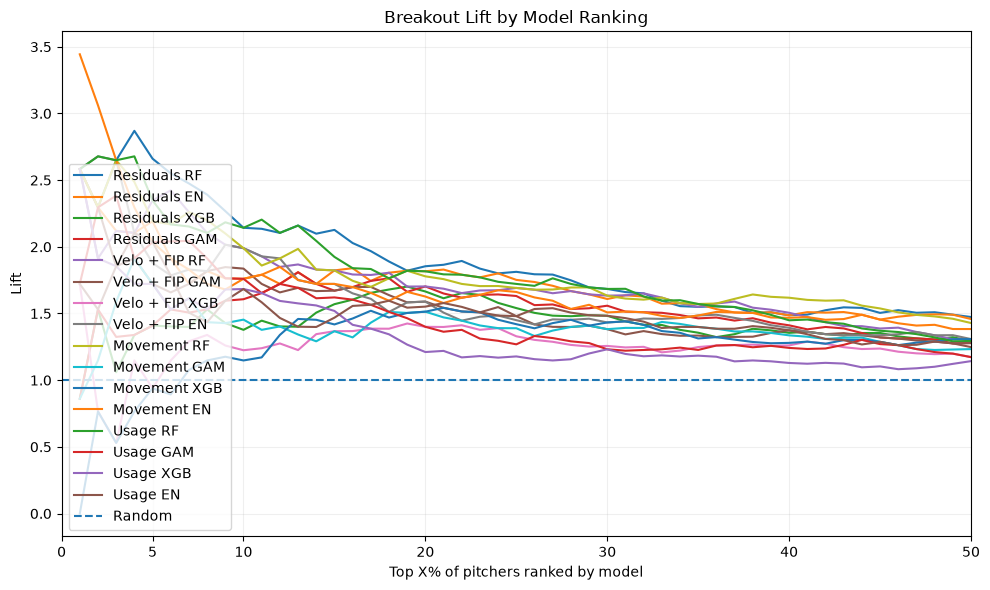

,Model,N,Breakouts,ROC-AUC,PR-AUC
0,Residuals RF,458,133,0.715928,0.527366
1,Usage RF,458,133,0.676831,0.494659
2,Movement RF,458,133,0.701261,0.490369
3,Velo + FIP RF,458,133,0.681272,0.478625
4,Residuals EN,458,133,0.693279,0.473149
...,...,...,...,...,...
11,Residuals XGB,458,133,0.643678,0.396559
12,Movement GAM,458,133,0.613534,0.386573
13,Movement XGB,458,133,0.633129,0.369362
14,Usage XGB,458,133,0.574112,0.368757


In [8]:
base_analysis.get_model_metrics()

In [9]:
base_analysis.results_df[['PlayerName', 'Season', 'score_residuals_rf', 'FIP-', 'led_to_breakout']].sort_values('score_residuals_rf', ascending=False)

,PlayerName,Season,score_residuals_rf,FIP-,led_to_breakout
1157,Gavin Williams,2025,12.532354,107.075247,True
3505,Walker Buehler,2025,12.487396,136.363482,False
136,Andre Pallante,2025,12.039059,114.949947,True
976,Dustin May,2025,11.929843,115.887572,True
2655,Nathan Eovaldi,2022,11.810288,108.521287,True
...,...,...,...,...,...
3398,Trevor Rogers,2021,-9.319663,60.517912,False
696,Clayton Kershaw,2022,-9.536456,63.841059,False
2102,Kevin Gausman,2022,-10.272365,59.721516,False
3194,Spencer Strider,2022,-15.782836,47.624203,False


In [10]:
helpy.breakout_rate_suite(base_analysis.results_df, 'score_residuals_rf', 'led_to_breakout')

Overall Breakout Rate: 29.04%
Top 5% Breakout Rate: 77.27%
Top 10% Breakout Rate: 62.22%
Top 25% Breakout Rate: 52.63%
Top 50% Breakout Rate: 42.79%


In [11]:
baseline_scores_df = helpy.create_baseline_breakout_model(analysis_df, training_range, testing_range)

In [17]:
baseline_scores_df[['score_fip', 'FIP-', 'led_to_breakout']].sort_values('score_fip', ascending=False)

,score_fip,FIP-,led_to_breakout
3165,0.443510,119.136311,False
139,0.443506,119.210677,True
215,0.443506,118.807209,False
2513,0.443500,119.299546,False
1325,0.443480,119.480978,False
...,...,...,...
2850,0.227167,62.124544,False
1139,0.226949,63.995447,False
2037,0.226942,63.121288,False
696,0.226934,63.841059,False


In [13]:
helpy.breakout_rate_suite(baseline_scores_df, 'score_fip', 'led_to_breakout')

Overall Breakout Rate: 29.04%
Top 5% Breakout Rate: 27.27%
Top 10% Breakout Rate: 42.22%
Top 25% Breakout Rate: 45.61%
Top 50% Breakout Rate: 38.86%


In [14]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)